In [1]:
import os
import numpy as np
import pandas as pd

print("Kaggle environment ready.")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

Kaggle environment ready.
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/wesad_readme.pdf
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_quest.csv
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_respiban.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_E4_Data/HR.csv
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_E4_Data/IBI.csv
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_E4_Data/BVP.csv
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_E4_Data/EDA.csv
/kaggle/input/datasets/orvile/wesad-wearable-

In [2]:
import pickle

BASE = "/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD"
S2 = f"{BASE}/S2"
E4 = f"{S2}/S2_E4_Data"

with open(f"{S2}/S2.pkl", "rb") as f:
    wesad = pickle.load(f, encoding="latin1")

bvp = pd.read_csv(f"{E4}/BVP.csv")
eda = pd.read_csv(f"{E4}/EDA.csv")
temp = pd.read_csv(f"{E4}/TEMP.csv")
acc = pd.read_csv(f"{E4}/ACC.csv")

print("S2 loaded successfully.")
print("BVP :", bvp.shape)
print("EDA :", eda.shape)
print("TEMP:", temp.shape)
print("ACC :", acc.shape)

S2 loaded successfully.
BVP : (503944, 1)
EDA : (31495, 1)
TEMP: (31497, 1)
ACC : (251971, 3)


In [3]:
print("BVP:")
display(bvp.head())

print("\nEDA:")
display(eda.head())

print("\nTEMP:")
display(temp.head())

print("\nACC:")
display(acc.head())

BVP:


,1495437325.00
0,64.0
1,-0.0
2,-0.0
3,-0.0
4,-0.0



EDA:


,1495437325.000000
0,4.000000
1,0.000000
2,0.328021
3,0.410026
4,0.433090



TEMP:


,1495437325.000000
0,4.00
1,382.18
2,382.18
3,382.18
4,382.18



ACC:


,1495437325.000000,1495437325.000000,1495437325.000000.1
0,32.0,32.0,32.0
1,29.0,-6.0,55.0
2,28.0,-6.0,55.0
3,28.0,-6.0,55.0
4,28.0,-6.0,55.0


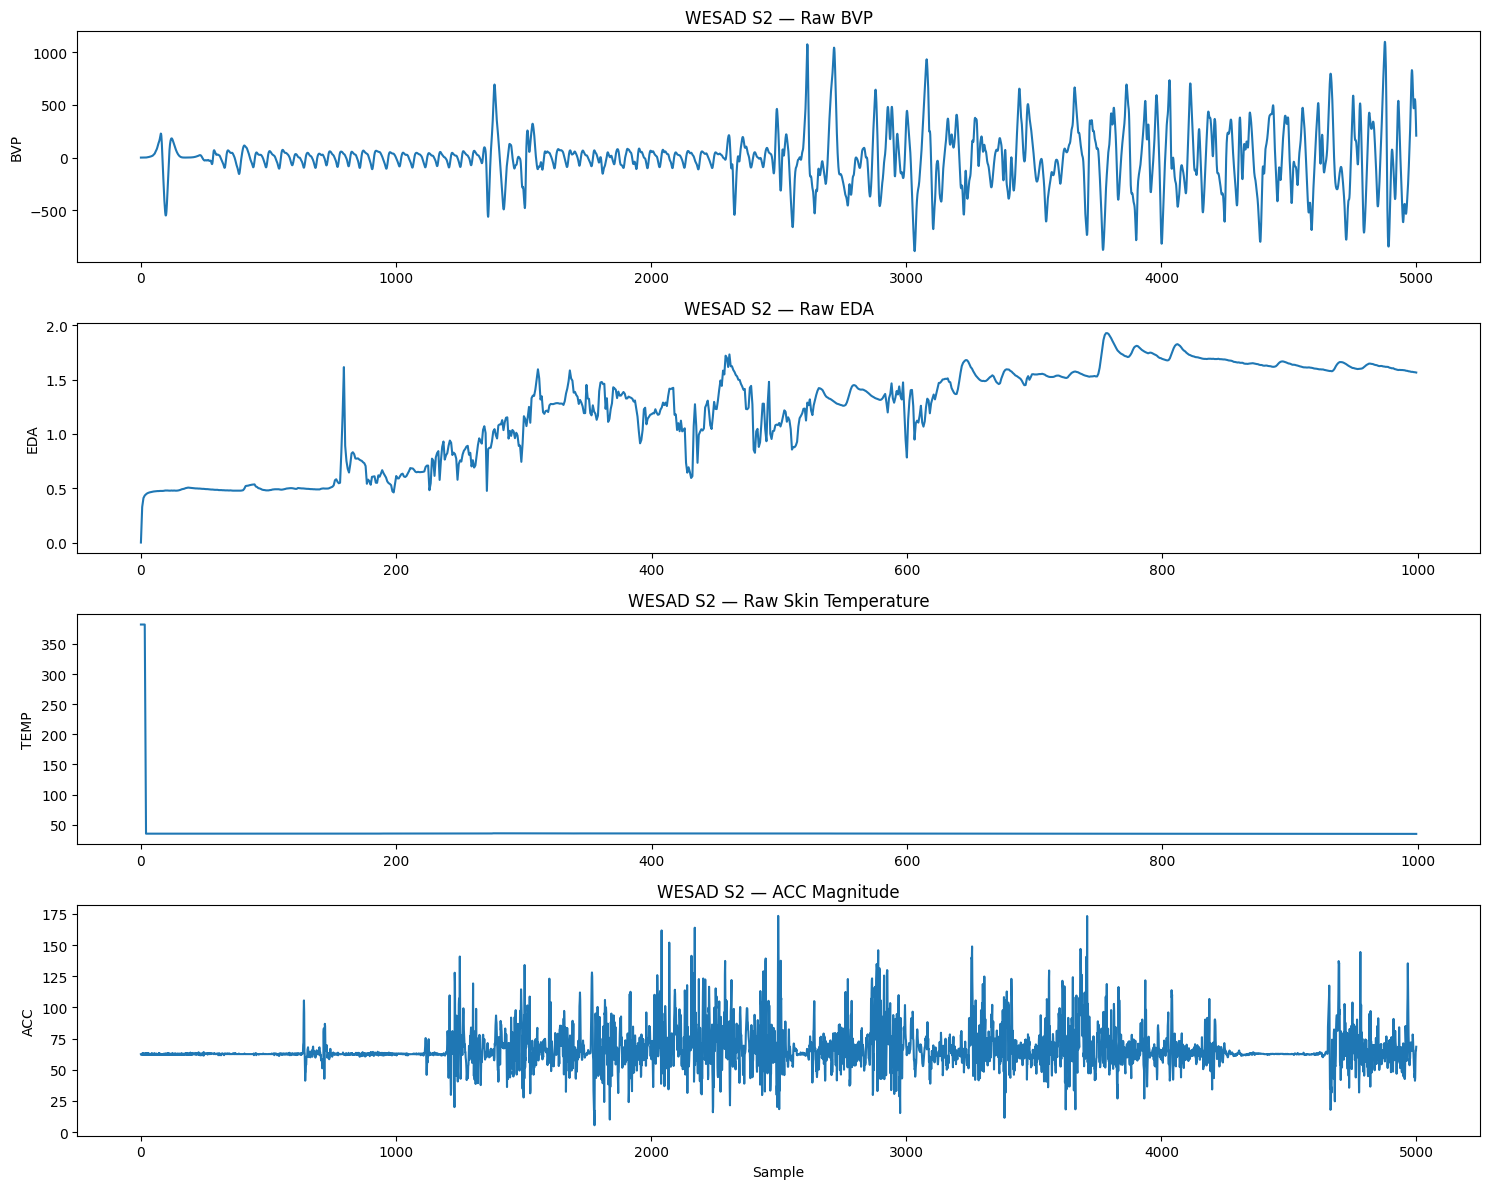

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 1, figsize=(15, 12))

# Skip the first metadata row
axes[0].plot(bvp.iloc[1:, 0].values[:5000])
axes[0].set_title("WESAD S2 — Raw BVP")
axes[0].set_ylabel("BVP")

axes[1].plot(eda.iloc[1:, 0].values[:1000])
axes[1].set_title("WESAD S2 — Raw EDA")
axes[1].set_ylabel("EDA")

axes[2].plot(temp.iloc[1:, 0].values[:1000])
axes[2].set_title("WESAD S2 — Raw Skin Temperature")
axes[2].set_ylabel("TEMP")

acc_values = acc.iloc[1:, :3].values[:5000]
acc_magnitude = np.sqrt(np.sum(acc_values ** 2, axis=1))

axes[3].plot(acc_magnitude)
axes[3].set_title("WESAD S2 — ACC Magnitude")
axes[3].set_ylabel("ACC")
axes[3].set_xlabel("Sample")

plt.tight_layout()
plt.show()

In [5]:
# Check WESAD label structure for S2

labels = np.asarray(wesad["label"]).flatten()

print("Total labels:", len(labels))
print("Unique label values:", np.unique(labels))

unique, counts = np.unique(labels, return_counts=True)

print("\nLabel counts:")
for label, count in zip(unique, counts):
    print(f"Label {label}: {count:,}")

Total labels: 4255300
Unique label values: [0 1 2 3 4 6 7]

Label counts:
Label 0: 2,142,701
Label 1: 800,800
Label 2: 430,500
Label 3: 253,400
Label 4: 537,599
Label 6: 45,500
Label 7: 44,800


In [6]:
readme_path = f"{S2}/S2_readme.txt"

with open(readme_path, "r", encoding="utf-8", errors="ignore") as f:
    readme = f.read()

print(readme)

### Personal information ###
Age: 27
Height (cm): 175
Weight (kg): 80
Gender: male
Dominant hand: right

### Study pre-requisites ###
Did you drink coffee today? NO
Did you drink coffee within the last hour? NO
Did you do any sports today? NO
Are you a smoker? NO
Did you smoke within the last hour? NO
Do you feel ill today? NO

### Additional notes ###
The RespiBAN temperature sensor was not fully attached throughout the entire duration of the study protocol.



In [7]:
print("WESAD keys:")
print(wesad.keys())

print("\nData keys:")
if "signal" in wesad:
    print(wesad["signal"].keys())

print("\nLabel dtype:", wesad["label"].dtype)
print("Label shape:", wesad["label"].shape)

WESAD keys:
dict_keys(['signal', 'label', 'subject'])

Data keys:
dict_keys(['chest', 'wrist'])

Label dtype: int32
Label shape: (4255300,)


In [8]:
print("Wrist channels:")
print(wesad["signal"]["wrist"].keys())

print("\nChest channels:")
print(wesad["signal"]["chest"].keys())

Wrist channels:
dict_keys(['ACC', 'BVP', 'EDA', 'TEMP'])

Chest channels:
dict_keys(['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'])


In [9]:
# WESAD wrist sampling rates
print("Wrist signal shapes:")

for name, data in wesad["signal"]["wrist"].items():
    print(f"{name:5}:", np.asarray(data).shape)

print("\nLabel shape:", wesad["label"].shape)

print("\nExpected samples in 60 seconds:")
print("BVP  :", 64 * 60)
print("EDA  :", 4 * 60)
print("TEMP :", 4 * 60)
print("ACC  :", 32 * 60)
print("Labels:", 700 * 60)

Wrist signal shapes:
ACC  : (194528, 3)
BVP  : (389056, 1)
EDA  : (24316, 1)
TEMP : (24316, 1)

Label shape: (4255300,)

Expected samples in 60 seconds:
BVP  : 3840
EDA  : 240
TEMP : 240
ACC  : 1920
Labels: 42000


In [10]:

import numpy as np

wrist = wesad["signal"]["wrist"]

temp = np.asarray(wrist["TEMP"]).flatten()

print("TEMPERATURE DIAGNOSTICS")
print("=======================")

print("First 30 values:")
print(temp[:30])

print("\nLast 30 values:")
print(temp[-30:])

print("\nStatistics:")
print("Minimum:", np.min(temp))
print("Maximum:", np.max(temp))
print("Mean:", np.mean(temp))
print("Median:", np.median(temp))
print("Standard deviation:", np.std(temp))

print("\nPercentiles:")
for p in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
    print(f"{p}%:", np.percentile(temp, p))

print("\nNon-finite values:", np.sum(~np.isfinite(temp)))


TEMPERATURE DIAGNOSTICS
First 30 values:
[35.41 35.41 35.41 35.41 35.41 35.41 35.41 35.41 35.41 35.41 35.41 35.41
 35.41 35.41 35.41 35.41 35.43 35.43 35.43 35.43 35.41 35.41 35.41 35.41
 35.43 35.43 35.43 35.43 35.41 35.41]

Last 30 values:
[34.21 34.21 34.23 34.23 34.23 34.23 34.21 34.21 34.21 34.21 34.21 34.21
 34.21 34.21 34.23 34.23 34.23 34.23 34.21 34.21 34.21 34.21 34.21 34.21
 34.21 34.21 34.23 34.23 34.23 34.23]

Statistics:
Minimum: 32.31
Maximum: 35.97
Mean: 34.38694522125349
Median: 34.25
Standard deviation: 1.0453181540679357

Percentiles:
0%: 32.31
1%: 32.34
5%: 32.59
25%: 33.68
50%: 34.25
75%: 35.41
95%: 35.89
99%: 35.93
100%: 35.97

Non-finite values: 0


In [11]:

labels = np.asarray(wesad["label"]).flatten()

unique, counts = np.unique(labels, return_counts=True)

print("LABEL DISTRIBUTION")
print("==================")

for label, count in zip(unique, counts):
    print(f"Label {label}: {count} samples")

print("\nTotal labels:", len(labels))


LABEL DISTRIBUTION
Label 0: 2142701 samples
Label 1: 800800 samples
Label 2: 430500 samples
Label 3: 253400 samples
Label 4: 537599 samples
Label 6: 45500 samples
Label 7: 44800 samples

Total labels: 4255300


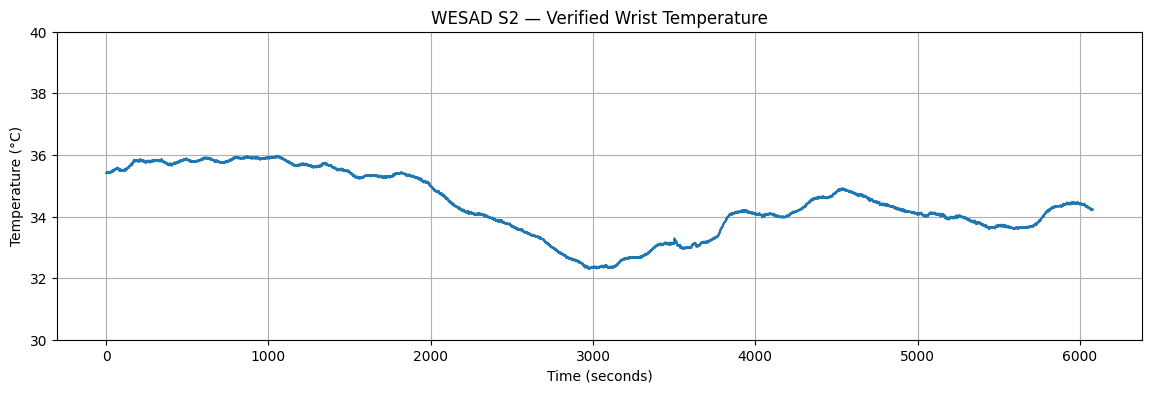

In [12]:
import matplotlib.pyplot as plt
import numpy as np

temp = np.asarray(wesad["signal"]["wrist"]["TEMP"]).flatten()

time_temp = np.arange(len(temp)) / 4

plt.figure(figsize=(14, 4))
plt.plot(time_temp, temp)

plt.title("WESAD S2 — Verified Wrist Temperature")
plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.ylim(30, 40)
plt.grid(True)
plt.show()

In [13]:
print("WESAD label mapping:")
print(wesad["label"].dtype)
print(np.unique(wesad["label"], return_counts=True))

WESAD label mapping:
int32
(array([0, 1, 2, 3, 4, 6, 7], dtype=int32), array([2142701,  800800,  430500,  253400,  537599,   45500,   44800]))


In [14]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "readme" in file.lower():
            print(os.path.join(root, file))

/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/wesad_readme.pdf
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S11/S11_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S13/S13_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S10/S10_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S8/S8_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S5/S5_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S7/S7_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S9/S9_readme.txt
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S15/S15_r

In [15]:

from pypdf import PdfReader

pdf_path = "/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/wesad_readme.pdf"

reader = PdfReader(pdf_path)

print("Number of pages:", len(reader.pages))

for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""

    if any(word in text.lower() for word in ["label", "baseline", "stress", "amusement", "meditation"]):
        print(f"\n========== PAGE {i+1} ==========")
        print(text)


Number of pages: 4

========== PAGE 1 ==========
WESAD Dataset: WEarable Stress and Affect Detection 
 
I. General information 
Contact persons: Philip Schmidt and Attila Reiss, contact at: firstname.lastname@de.bosch.com. 
If you publish material based on this dataset, please reference the publication [1]. 
I.1. Dataset structure 
The dataset is organised so that each subject has a folder (SX, where X = subject ID). Each subject 
folder contains the following files: 
  - SX_readme.txt: contains information about the subject (SX) and information about data collection 
and data quality (if applicable) 
  - SX_quest.csv: contains all relevant information to obtain ground truth, including the protocol 
schedule for SX and answers to the self-report questionnaires; see details below 
  - SX_respiban.txt: contains data from the RespiBAN device; see details below 
  - SX_E4_Data.zip: contains data from the Empatica E4 device; see details below 
  - SX.pkl: contains synchronised data and labe

In [16]:

s2_path = "/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S2/S2_readme.txt"

with open(s2_path, "r", encoding="utf-8") as f:
    s2_text = f.read()

print(s2_text)


### Personal information ###
Age: 27
Height (cm): 175
Weight (kg): 80
Gender: male
Dominant hand: right

### Study pre-requisites ###
Did you drink coffee today? NO
Did you drink coffee within the last hour? NO
Did you do any sports today? NO
Are you a smoker? NO
Did you smoke within the last hour? NO
Do you feel ill today? NO

### Additional notes ###
The RespiBAN temperature sensor was not fully attached throughout the entire duration of the study protocol.



In [17]:
labels = np.asarray(wesad["label"]).flatten()

baseline_count = np.sum(labels == 1)
stress_count = np.sum(labels == 2)
excluded_count = np.sum((labels != 1) & (labels != 2))

print("Baseline:", baseline_count)
print("Stress:", stress_count)
print("Excluded:", excluded_count)
print("Total:", len(labels))

Baseline: 800800
Stress: 430500
Excluded: 3024000
Total: 4255300


In [18]:

import numpy as np

wrist = wesad["signal"]["wrist"]

sensor_data = {
    "ACC": np.asarray(wrist["ACC"]),
    "BVP": np.asarray(wrist["BVP"]),
    "EDA": np.asarray(wrist["EDA"]),
    "TEMP": np.asarray(wrist["TEMP"])
}

for name, signal in sensor_data.items():
    print(f"\n{name}")
    print("Shape:", signal.shape)
    print("NaN values:", np.isnan(signal).sum())
    print("Infinite values:", np.isinf(signal).sum())
    print("Minimum:", np.nanmin(signal))
    print("Maximum:", np.nanmax(signal))



ACC
Shape: (194528, 3)
NaN values: 0
Infinite values: 0
Minimum: -128.0
Maximum: 127.0

BVP
Shape: (389056, 1)
NaN values: 0
Infinite values: 0
Minimum: -873.67
Maximum: 988.08

EDA
Shape: (24316, 1)
NaN values: 0
Infinite values: 0
Minimum: 0.045113
Maximum: 1.717419

TEMP
Shape: (24316, 1)
NaN values: 0
Infinite values: 0
Minimum: 32.31
Maximum: 35.97


In [19]:

# Convert wrist accelerometer values from raw units to g
acc_g = sensor_data["ACC"].astype(np.float32) / 64.0

print("Original ACC range:",
      sensor_data["ACC"].min(),
      "to",
      sensor_data["ACC"].max())

print("\nConverted ACC range:",
      acc_g.min(),
      "to",
      acc_g.max())

print("\nConverted ACC shape:", acc_g.shape)


Original ACC range: -128.0 to 127.0

Converted ACC range: -2.0 to 1.984375

Converted ACC shape: (194528, 3)


In [20]:

# Prepare sensor arrays for preprocessing

sensor_data_clean = {
    "ACC": acc_g.astype(np.float32),
    "BVP": sensor_data["BVP"].astype(np.float32).flatten(),
    "EDA": sensor_data["EDA"].astype(np.float32).flatten(),
    "TEMP": sensor_data["TEMP"].astype(np.float32).flatten()
}

for name, signal in sensor_data_clean.items():
    print(
        name,
        "| Shape:", signal.shape,
        "| Data type:", signal.dtype
    )


ACC | Shape: (194528, 3) | Data type: float32
BVP | Shape: (389056,) | Data type: float32
EDA | Shape: (24316,) | Data type: float32
TEMP | Shape: (24316,) | Data type: float32


In [21]:

sampling_rates = {
    "ACC": 32,
    "BVP": 64,
    "EDA": 4,
    "TEMP": 4
}

for name, signal in sensor_data_clean.items():
    duration = len(signal) / sampling_rates[name]
    print(f"{name}: {duration:.2f} seconds ({duration / 60:.2f} minutes)")


ACC: 6079.00 seconds (101.32 minutes)
BVP: 6079.00 seconds (101.32 minutes)
EDA: 6079.00 seconds (101.32 minutes)
TEMP: 6079.00 seconds (101.32 minutes)


In [22]:

import scipy

print("SciPy version:", scipy.__version__)


SciPy version: 1.16.3


In [23]:

from scipy.signal import resample_poly

# Downsample ACC from 32 Hz to 4 Hz
acc_4hz = resample_poly(
    sensor_data_clean["ACC"],
    up=1,
    down=8,
    axis=0
)

print("Original ACC shape:", sensor_data_clean["ACC"].shape)
print("Resampled ACC shape:", acc_4hz.shape)

print("Original sampling rate: 32 Hz")
print("New sampling rate: 4 Hz")

print("Original duration:",
      len(sensor_data_clean["ACC"]) / 32, "seconds")

print("Resampled duration:",
      len(acc_4hz) / 4, "seconds")


Original ACC shape: (194528, 3)
Resampled ACC shape: (24316, 3)
Original sampling rate: 32 Hz
New sampling rate: 4 Hz
Original duration: 6079.0 seconds
Resampled duration: 6079.0 seconds


In [24]:

# Downsample BVP from 64 Hz to 4 Hz
bvp_4hz = resample_poly(
    sensor_data_clean["BVP"],
    up=1,
    down=16
)

print("Original BVP shape:", sensor_data_clean["BVP"].shape)
print("Resampled BVP shape:", bvp_4hz.shape)

print("Original sampling rate: 64 Hz")
print("New sampling rate: 4 Hz")

print("Original duration:",
      len(sensor_data_clean["BVP"]) / 64, "seconds")

print("Resampled duration:",
      len(bvp_4hz) / 4, "seconds")


Original BVP shape: (389056,)
Resampled BVP shape: (24316,)
Original sampling rate: 64 Hz
New sampling rate: 4 Hz
Original duration: 6079.0 seconds
Resampled duration: 6079.0 seconds


In [25]:

aligned_sensors = {
    "ACC": acc_4hz,
    "BVP": bvp_4hz,
    "EDA": sensor_data_clean["EDA"],
    "TEMP": sensor_data_clean["TEMP"]
}

for name, signal in aligned_sensors.items():
    print(f"{name}: {signal.shape}")

lengths = [len(signal) for signal in aligned_sensors.values()]

print("\nAll sensors have equal length:", len(set(lengths)) == 1)


ACC: (24316, 3)
BVP: (24316,)
EDA: (24316,)
TEMP: (24316,)

All sensors have equal length: True


In [26]:

sensor_matrix = np.column_stack([
    aligned_sensors["ACC"],
    aligned_sensors["BVP"],
    aligned_sensors["EDA"],
    aligned_sensors["TEMP"]
])

print("Combined sensor matrix shape:", sensor_matrix.shape)
print("Data type:", sensor_matrix.dtype)
print("Contains NaN:", np.isnan(sensor_matrix).any())
print("Contains infinity:", np.isinf(sensor_matrix).any())


Combined sensor matrix shape: (24316, 6)
Data type: float32
Contains NaN: False
Contains infinity: False


In [27]:

WINDOW_SECONDS = 60

sampling_rates = {
    "ACC": 32,
    "BVP": 64,
    "EDA": 4,
    "TEMP": 4
}

samples_per_window = {
    sensor: rate * WINDOW_SECONDS
    for sensor, rate in sampling_rates.items()
}

print("Window duration:", WINDOW_SECONDS, "seconds")
print("\nSamples per 60-second window:")

for sensor, count in samples_per_window.items():
    print(f"{sensor}: {count} samples")


Window duration: 60 seconds

Samples per 60-second window:
ACC: 1920 samples
BVP: 3840 samples
EDA: 240 samples
TEMP: 240 samples


In [28]:

total_duration = 6079

num_windows = total_duration // WINDOW_SECONDS
remaining_seconds = total_duration % WINDOW_SECONDS

print("Total recording duration:", total_duration, "seconds")
print("Complete 60-second windows:", num_windows)
print("Remaining duration:", remaining_seconds, "seconds")


Total recording duration: 6079 seconds
Complete 60-second windows: 101
Remaining duration: 19 seconds


In [29]:

windowed_sensors = {}

for sensor, signal in sensor_data_clean.items():
    samples = samples_per_window[sensor]

    usable_length = num_windows * samples

    windowed_sensors[sensor] = signal[:usable_length].reshape(
        num_windows, samples, *signal.shape[1:]
    )

for sensor, windows in windowed_sensors.items():
    print(f"{sensor}: {windows.shape}")


ACC: (101, 1920, 3)
BVP: (101, 3840)
EDA: (101, 240)
TEMP: (101, 240)


In [30]:

for sensor, windows in windowed_sensors.items():
    print(
        f"{sensor} | "
        f"NaN: {np.isnan(windows).sum()} | "
        f"Inf: {np.isinf(windows).sum()}"
    )


ACC | NaN: 0 | Inf: 0
BVP | NaN: 0 | Inf: 0
EDA | NaN: 0 | Inf: 0
TEMP | NaN: 0 | Inf: 0


In [31]:

print("Original label shape:", wesad["label"].shape)
print("Label sampling rate: 700 Hz")
print("Labels in first 20 samples:", wesad["label"][:20])


Original label shape: (4255300,)
Label sampling rate: 700 Hz
Labels in first 20 samples: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [32]:

LABEL_RATE = 700
labels_per_window = WINDOW_SECONDS * LABEL_RATE

usable_label_length = num_windows * labels_per_window

label_windows = wesad["label"][:usable_label_length].reshape(
    num_windows, labels_per_window
)

print("Label window shape:", label_windows.shape)
print("\nLabel counts in the first 10 windows:")

for i in range(10):
    unique, counts = np.unique(label_windows[i], return_counts=True)
    print(f"Window {i}: {dict(zip(unique.tolist(), counts.tolist()))}")


Label window shape: (101, 42000)

Label counts in the first 10 windows:
Window 0: {0: 42000}
Window 1: {0: 42000}
Window 2: {0: 42000}
Window 3: {0: 42000}
Window 4: {0: 42000}
Window 5: {0: 4583, 1: 37417}
Window 6: {1: 42000}
Window 7: {1: 42000}
Window 8: {1: 42000}
Window 9: {1: 42000}


In [33]:

window_categories = {
    "Pure baseline": 0,
    "Pure stress": 0,
    "Mixed baseline/stress": 0,
    "Only excluded labels": 0,
    "Valid + excluded labels": 0
}

for window in label_windows:
    unique_labels = set(np.unique(window))

    if unique_labels == {1}:
        window_categories["Pure baseline"] += 1
    elif unique_labels == {2}:
        window_categories["Pure stress"] += 1
    elif unique_labels == {1, 2}:
        window_categories["Mixed baseline/stress"] += 1
    elif not unique_labels.intersection({1, 2}):
        window_categories["Only excluded labels"] += 1
    else:
        window_categories["Valid + excluded labels"] += 1

for category, count in window_categories.items():
    print(f"{category}: {count}")


Pure baseline: 18
Pure stress: 10
Mixed baseline/stress: 0
Only excluded labels: 69
Valid + excluded labels: 4


In [34]:

valid_window_indices = []
window_targets = []

for i, window in enumerate(label_windows):
    unique_labels = np.unique(window)

    if len(unique_labels) == 1 and unique_labels[0] == 1:
        valid_window_indices.append(i)
        window_targets.append(0)

    elif len(unique_labels) == 1 and unique_labels[0] == 2:
        valid_window_indices.append(i)
        window_targets.append(1)

valid_window_indices = np.array(valid_window_indices)
window_targets = np.array(window_targets, dtype=np.int32)

print("Valid windows:", len(valid_window_indices))
print("Baseline windows:", np.sum(window_targets == 0))
print("Stress windows:", np.sum(window_targets == 1))
print("Target shape:", window_targets.shape)


Valid windows: 28
Baseline windows: 18
Stress windows: 10
Target shape: (28,)


In [35]:

valid_sensor_windows = {}

for sensor, windows in windowed_sensors.items():
    valid_sensor_windows[sensor] = windows[valid_window_indices]

for sensor, windows in valid_sensor_windows.items():
    print(f"{sensor}: {windows.shape}")


ACC: (28, 1920, 3)
BVP: (28, 3840)
EDA: (28, 240)
TEMP: (28, 240)


In [36]:

import numpy as np
import pandas as pd

def signal_slope(values):
    values = np.asarray(values, dtype=np.float64)
    if len(values) < 2:
        return 0.0

    x_mean = (len(values) - 1) / 2
    y_mean = np.mean(values)
    denominator = np.sum((np.arange(len(values)) - x_mean) ** 2)

    return float(
        np.sum((np.arange(len(values)) - x_mean) * (values - y_mean))
        / denominator
    )


def local_maxima(values, threshold, minimum_distance):
    candidates = [
        i for i in range(1, len(values) - 1)
        if values[i] > values[i - 1]
        and values[i] >= values[i + 1]
        and values[i] > threshold
    ]

    selected = []

    for i in candidates:
        if not selected or i - selected[-1] >= minimum_distance:
            selected.append(i)
        elif values[i] > values[selected[-1]]:
            selected[-1] = i

    return selected


def extract_features(i):
    bvp = valid_sensor_windows["BVP"][i].astype(np.float64)
    eda = valid_sensor_windows["EDA"][i].astype(np.float64)
    temp = valid_sensor_windows["TEMP"][i].astype(np.float64)
    acc = valid_sensor_windows["ACC"][i].astype(np.float64)

    features = {}

    # BVP features
    features.update({
        "bvp_mean": np.mean(bvp),
        "bvp_std": np.std(bvp),
        "bvp_range": np.max(bvp) - np.min(bvp),
        "bvp_slope": signal_slope(bvp),
        "bvp_rms": np.sqrt(np.mean(bvp ** 2))
    })

    # EDA features
    eda_median = np.median(eda)
    eda_mad = np.median(np.abs(eda - eda_median))
    eda_threshold = eda_median + max(0.05, 3.0 * eda_mad)

    eda_peaks = local_maxima(
        eda,
        eda_threshold,
        minimum_distance=4
    )

    peak_amplitudes = [eda[p] - eda_median for p in eda_peaks]

    features.update({
        "eda_mean": np.mean(eda),
        "eda_std": np.std(eda),
        "eda_range": np.max(eda) - np.min(eda),
        "eda_slope": signal_slope(eda),
        "eda_peak_count": float(len(eda_peaks)),
        "eda_peak_mean_amplitude": (
            np.mean(peak_amplitudes) if peak_amplitudes else 0.0
        ),
        "eda_peak_max_amplitude": (
            np.max(peak_amplitudes) if peak_amplitudes else 0.0
        )
    })

    # Skin temperature features
    features.update({
        "skin_temperature_mean": np.mean(temp),
        "skin_temperature_std": np.std(temp),
        "skin_temperature_range": np.max(temp) - np.min(temp),
        "skin_temperature_slope": signal_slope(temp)
    })

    # Individual ACC axis features
    for axis, values in zip(("x", "y", "z"), acc.T):
        features.update({
            f"acc_{axis}_mean": np.mean(values),
            f"acc_{axis}_std": np.std(values)
        })

    # ACC magnitude features
    magnitude = np.sqrt(np.sum(acc ** 2, axis=1))

    features.update({
        "acc_magnitude_mean": np.mean(magnitude),
        "acc_magnitude_std": np.std(magnitude),
        "acc_magnitude_range": np.max(magnitude) - np.min(magnitude),
        "acc_magnitude_rms": np.sqrt(np.mean(magnitude ** 2)),
        "acc_magnitude_mean_abs_diff": np.mean(np.abs(np.diff(magnitude)))
    })

    return features


# Extract features from all 28 valid windows
feature_rows = [extract_features(i) for i in range(len(window_targets))]
feature_df = pd.DataFrame(feature_rows)

# Match the exact feature order used by the project
feature_order = [
    "bvp_mean", "bvp_std", "bvp_range", "bvp_slope", "bvp_rms",
    "eda_mean", "eda_std", "eda_range", "eda_slope",
    "eda_peak_count", "eda_peak_mean_amplitude", "eda_peak_max_amplitude",
    "skin_temperature_mean", "skin_temperature_std",
    "skin_temperature_range", "skin_temperature_slope",
    "acc_x_mean", "acc_x_std", "acc_y_mean", "acc_y_std",
    "acc_z_mean", "acc_z_std",
    "acc_magnitude_mean", "acc_magnitude_std",
    "acc_magnitude_range", "acc_magnitude_rms",
    "acc_magnitude_mean_abs_diff"
]

feature_df = feature_df[feature_order]

# Final feature matrix and target
X = feature_df.to_numpy(dtype=np.float32)
y = window_targets.copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", len(feature_order))
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("\nFeature names:")
print(feature_df.columns.tolist())


Feature matrix shape: (28, 27)
Target shape: (28,)
Number of features: 27
NaN values: 0
Infinite values: 0

Feature names:
['bvp_mean', 'bvp_std', 'bvp_range', 'bvp_slope', 'bvp_rms', 'eda_mean', 'eda_std', 'eda_range', 'eda_slope', 'eda_peak_count', 'eda_peak_mean_amplitude', 'eda_peak_max_amplitude', 'skin_temperature_mean', 'skin_temperature_std', 'skin_temperature_range', 'skin_temperature_slope', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'acc_magnitude_mean', 'acc_magnitude_std', 'acc_magnitude_range', 'acc_magnitude_rms', 'acc_magnitude_mean_abs_diff']


In [37]:

print("FEATURE STATISTICS")
display(feature_df.describe().T.round(4))

print("\nCONSTANT FEATURES:")
constant_features = feature_df.columns[
    feature_df.nunique() <= 1
].tolist()
print(constant_features if constant_features else "None")

print("\nFEATURE VARIANCE:")
print(feature_df.var().round(6))

print("\nCLASS-WISE FEATURE MEANS:")
class_means = feature_df.assign(target=y).groupby("target").mean().T
class_means.columns = ["Baseline (0)", "Stress (1)"]
display(class_means.round(4))


FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
bvp_mean,28.0,0.0306,0.3767,-0.9175,-0.1381,0.0113,0.1974,0.9168
bvp_std,28.0,57.5251,31.3324,20.5207,34.7029,45.1410,79.7349,136.8875
bvp_range,28.0,673.1982,329.6136,96.4500,405.4100,614.2750,888.0375,1323.2400
bvp_slope,28.0,-0.0002,0.0006,-0.0014,-0.0005,-0.0003,0.0000,0.0014
bvp_rms,28.0,57.5261,31.3328,20.5211,34.7041,45.1417,79.7349,136.8901
eda_mean,28.0,0.4698,0.3685,0.0943,0.1187,0.3844,0.7366,1.1489
eda_std,28.0,0.0292,0.0316,0.0012,0.0085,0.0204,0.0374,0.1521
eda_range,28.0,0.1203,0.1098,0.0064,0.0381,0.0910,0.1512,0.5190
eda_slope,28.0,-0.0001,0.0005,-0.0021,-0.0003,-0.0000,0.0000,0.0010
eda_peak_count,28.0,0.6429,1.0261,0.0000,0.0000,0.0000,1.0000,4.0000



CONSTANT FEATURES:
None

FEATURE VARIANCE:
bvp_mean                            0.141873
bvp_std                           981.720608
bvp_range                      108645.100744
bvp_slope                           0.000000
bvp_rms                           981.741615
eda_mean                            0.135802
eda_std                             0.000999
eda_range                           0.012048
eda_slope                           0.000000
eda_peak_count                      1.052910
eda_peak_mean_amplitude             0.007018
eda_peak_max_amplitude              0.007367
skin_temperature_mean               1.385574
skin_temperature_std                0.000214
skin_temperature_range              0.002314
skin_temperature_slope              0.000000
acc_x_mean                          0.065747
acc_x_std                           0.007149
acc_y_mean                          0.361296
acc_y_std                           0.002202
acc_z_mean                          0.107612
acc_z_std  

,Baseline (0),Stress (1)
bvp_mean,0.0575,-0.0178
bvp_std,52.7853,66.0567
bvp_range,654.7078,706.4810
bvp_slope,-0.0002,-0.0001
bvp_rms,52.7867,66.0571
eda_mean,0.2494,0.8666
eda_std,0.0232,0.0400
eda_range,0.0914,0.1722
eda_slope,-0.0003,0.0001
eda_peak_count,0.1111,1.6000


In [38]:

correlation_matrix = feature_df.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = ["Feature 1", "Feature 2", "Absolute Correlation"]

high_correlations = high_correlations[
    high_correlations["Absolute Correlation"] >= 0.90
].sort_values("Absolute Correlation", ascending=False)

print("Highly correlated feature pairs (|r| >= 0.90):")

if high_correlations.empty:
    print("No highly correlated pairs found.")
else:
    display(high_correlations.round(4))


Highly correlated feature pairs (|r| >= 0.90):


,Feature 1,Feature 2,Absolute Correlation
28,bvp_std,bvp_rms,1.0000
215,eda_peak_mean_amplitude,eda_peak_max_amplitude,0.9964
141,eda_std,eda_range,0.9869
343,acc_magnitude_mean,acc_magnitude_rms,0.9816
251,skin_temperature_mean,acc_y_mean,0.9659
297,acc_x_mean,acc_y_mean,0.9628
260,skin_temperature_std,skin_temperature_range,0.9587
249,skin_temperature_mean,acc_x_mean,0.9515


In [39]:

class_counts = pd.Series(y).value_counts().sort_index()
class_percentages = (class_counts / len(y) * 100).round(2)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary.index = ["Baseline (0)", "Stress (1)"]

display(class_summary)

print("Majority/minority ratio:",
      round(class_counts.max() / class_counts.min(), 2))


,Count,Percentage
Baseline (0),18,64.29
Stress (1),10,35.71


Majority/minority ratio: 1.8


In [40]:

from sklearn.ensemble import RandomForestClassifier

print("Training data verification")
print("--------------------------")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature count:", X.shape[1])
print("Class distribution:", dict(zip(*np.unique(y, return_counts=True))))
print("Data type:", X.dtype)
print("Missing values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

assert X.shape == (28, 27)
assert y.shape == (28,)
assert np.isfinite(X).all()
assert set(np.unique(y)) == {0, 1}

print("\nTraining data verification passed.")


Training data verification
--------------------------
X shape: (28, 27)
y shape: (28,)
Feature count: 27
Class distribution: {np.int32(0): np.int64(18), np.int32(1): np.int64(10)}
Data type: float32
Missing values: 0
Infinite values: 0

Training data verification passed.


In [41]:

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X, y)

print("Random Forest training completed.")
print("Number of trees:", rf_model.n_estimators)
print("Number of input features:", rf_model.n_features_in_)
print("Classes learned:", rf_model.classes_)


Random Forest training completed.
Number of trees: 300
Number of input features: 27
Classes learned: [0 1]


In [42]:

predictions = rf_model.predict(X)
probabilities = rf_model.predict_proba(X)

print("First 10 predictions:")
print(predictions[:10])

print("\nFirst 10 actual labels:")
print(y[:10])

print("\nFirst 10 prediction probabilities:")
print(np.round(probabilities[:10], 3))

print("\nPrediction output shape:", predictions.shape)
print("Probability output shape:", probabilities.shape)


First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 prediction probabilities:
[[0.873 0.127]
 [0.9   0.1  ]
 [0.983 0.017]
 [0.953 0.047]
 [1.    0.   ]
 [0.987 0.013]
 [0.92  0.08 ]
 [1.    0.   ]
 [0.99  0.01 ]
 [1.    0.   ]]

Prediction output shape: (28,)
Probability output shape: (28, 2)


In [43]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Training Accuracy:",
      round(accuracy_score(y, predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y, predictions))

print("\nClassification Report:")
print(classification_report(
    y,
    predictions,
    target_names=["Baseline", "Stress"],
    zero_division=0
))

Training Accuracy: 1.0

Confusion Matrix:
[[18  0]
 [ 0 10]]

Classification Report:
              precision    recall  f1-score   support

    Baseline       1.00      1.00      1.00        18
      Stress       1.00      1.00      1.00        10

    accuracy                           1.00        28
   macro avg       1.00      1.00      1.00        28
weighted avg       1.00      1.00      1.00        28



Top 10 Important Features:


,Feature,Importance
18,acc_y_mean,0.174643
16,acc_x_mean,0.143262
12,skin_temperature_mean,0.139905
5,eda_mean,0.101999
11,eda_peak_max_amplitude,0.055134
21,acc_z_std,0.048259
10,eda_peak_mean_amplitude,0.044966
7,eda_range,0.037734
15,skin_temperature_slope,0.036543
22,acc_magnitude_mean,0.034881


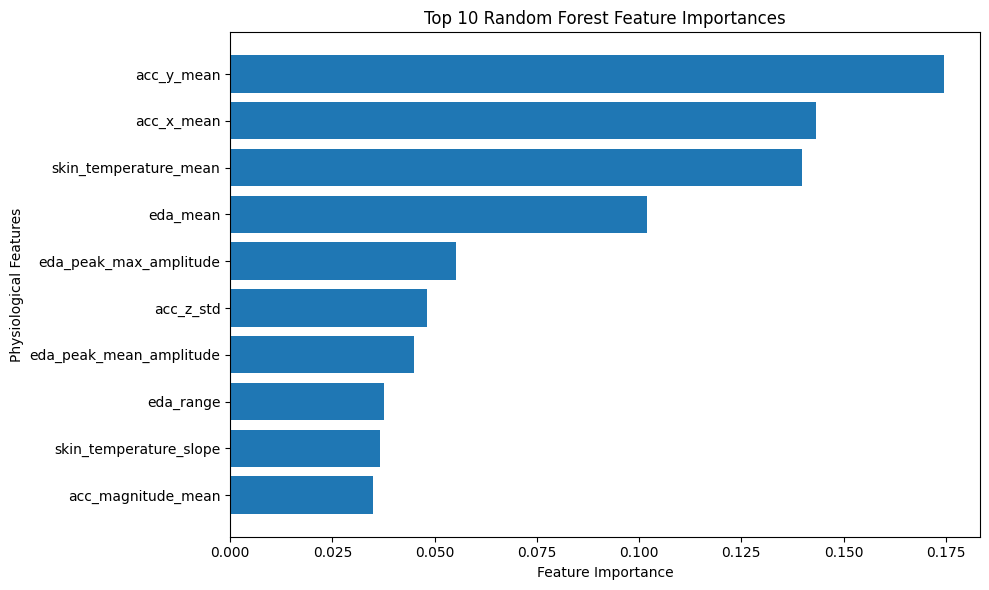

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": feature_order,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance.head(10)["Feature"][::-1],
    feature_importance.head(10)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Physiological Features")
plt.title("Top 10 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [45]:
import os

DATASET_PATH = "/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset"

print("Dataset directory exists:", os.path.exists(DATASET_PATH))

print("\nDataset contents:")
for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Dataset directory exists: True

Dataset contents:
wesad-wearable-stress-affect-detection-dataset/
    WESAD/
        wesad_readme.pdf
        S14/
            S14.pkl
            S14_quest.csv
            S14_respiban.txt
            S14_readme.txt
            S14_E4_Data/
                HR.csv
                IBI.csv
                BVP.csv
                EDA.csv
                info.txt
                TEMP.csv
                ACC.csv
                tags.csv
        S11/
            S11_respiban.txt
            S11.pkl
            S11_quest.csv
            S11_readme.txt
            S11_E4_Data/
                HR.csv
                IBI.csv
                BVP.csv
                EDA.csv
                info.txt
                TEMP.csv
                ACC.csv
                tags.csv
        S13/
            S13.pkl
            S13_respiban.txt
            S13_readme.txt
            S13_quest.csv
            S13_E4_Data/
                HR.csv
                IBI.csv
           

In [49]:
import os
import re

subject_files = []

for root, dirs, files in os.walk(WESAD_PATH):
    for file in files:
        if re.fullmatch(r"S\d+\.pkl", file):
            subject_files.append(os.path.join(root, file))

subject_files = sorted(
    subject_files,
    key=lambda x: int(
        re.search(r"S(\d+)", os.path.basename(x)).group(1)
    )
)

print("Total subjects:", len(subject_files))

for path in subject_files:
    print(path)

Total subjects: 15
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S2/S2.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S3/S3.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S4/S4.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S5/S5.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S6/S6.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S7/S7.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S8/S8.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S9/S9.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S10/S10.pkl
/kaggle/input/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/WESAD/S11/S11.pkl
/kaggle/input/datasets/orvile/wesad-wearable-st

In [48]:
import pickle
import numpy as np

subject_summary = []

for path in subject_files:

    subject_id = os.path.basename(path).replace(".pkl", "")

    with open(path, "rb") as file:
        data = pickle.load(file, encoding="latin1")

    wrist = data["signal"]["wrist"]
    labels = np.asarray(data["label"])

    subject_summary.append({
        "Subject": subject_id,
        "ACC": np.asarray(wrist["ACC"]).shape,
        "BVP": np.asarray(wrist["BVP"]).shape,
        "EDA": np.asarray(wrist["EDA"]).shape,
        "TEMP": np.asarray(wrist["TEMP"]).shape,
        "Labels": labels.shape,
        "Label_Count": len(np.unique(labels))
    })

    del data

import pandas as pd

subject_summary_df = pd.DataFrame(subject_summary)

display(subject_summary_df)

""


In [50]:
import pickle
import numpy as np
import pandas as pd
import os

subject_summary = []

for path in subject_files:

    subject_id = os.path.basename(path).replace(".pkl", "")

    with open(path, "rb") as file:
        data = pickle.load(file, encoding="latin1")

    wrist = data["signal"]["wrist"]
    labels = np.asarray(data["label"])

    row = {
        "Subject": subject_id,
        "Labels": len(labels)
    }

    for sensor in ["ACC", "BVP", "EDA", "TEMP"]:
        signal = np.asarray(wrist[sensor])

        row[f"{sensor}_Shape"] = signal.shape
        row[f"{sensor}_NaN"] = np.isnan(signal).sum()
        row[f"{sensor}_Inf"] = np.isinf(signal).sum()

    subject_summary.append(row)
    del data

subject_summary_df = pd.DataFrame(subject_summary)

display(subject_summary_df)

,Subject,Labels,ACC_Shape,ACC_NaN,ACC_Inf,BVP_Shape,BVP_NaN,BVP_Inf,EDA_Shape,EDA_NaN,EDA_Inf,TEMP_Shape,TEMP_NaN,TEMP_Inf
0,S2,4255300,"(194528, 3)",0,0,"(389056, 1)",0,0,"(24316, 1)",0,0,"(24316, 1)",0,0
1,S3,4545100,"(207776, 3)",0,0,"(415552, 1)",0,0,"(25972, 1)",0,0,"(25972, 1)",0,0
2,S4,4496100,"(205536, 3)",0,0,"(411072, 1)",0,0,"(25692, 1)",0,0,"(25692, 1)",0,0
3,S5,4380600,"(200256, 3)",0,0,"(400512, 1)",0,0,"(25032, 1)",0,0,"(25032, 1)",0,0
4,S6,4949700,"(226272, 3)",0,0,"(452544, 1)",0,0,"(28284, 1)",0,0,"(28284, 1)",0,0
5,S7,3666600,"(167616, 3)",0,0,"(335232, 1)",0,0,"(20952, 1)",0,0,"(20952, 1)",0,0
6,S8,3826200,"(174912, 3)",0,0,"(349824, 1)",0,0,"(21864, 1)",0,0,"(21864, 1)",0,0
7,S9,3656100,"(167136, 3)",0,0,"(334272, 1)",0,0,"(20892, 1)",0,0,"(20892, 1)",0,0
8,S10,3847200,"(175872, 3)",0,0,"(351744, 1)",0,0,"(21984, 1)",0,0,"(21984, 1)",0,0
9,S11,3663100,"(167456, 3)",0,0,"(334912, 1)",0,0,"(20932, 1)",0,0,"(20932, 1)",0,0


In [51]:
import pickle
import numpy as np
import os

SAMPLING_RATES = {
    "ACC": 32,
    "BVP": 64,
    "EDA": 4,
    "TEMP": 4
}

all_subject_data = {}

for path in subject_files:

    subject_id = os.path.basename(path).replace(".pkl", "")

    with open(path, "rb") as file:
        data = pickle.load(file, encoding="latin1")

    wrist = data["signal"]["wrist"]

    all_subject_data[subject_id] = {
        "ACC": np.asarray(wrist["ACC"], dtype=np.float32) / 64.0,
        "BVP": np.asarray(wrist["BVP"], dtype=np.float32).flatten(),
        "EDA": np.asarray(wrist["EDA"], dtype=np.float32).flatten(),
        "TEMP": np.asarray(wrist["TEMP"], dtype=np.float32).flatten(),
        "labels": np.asarray(data["label"])
    }

    del data

print("Loaded subjects:", len(all_subject_data))

for subject_id, signals in all_subject_data.items():
    print(
        subject_id,
        "| ACC:", signals["ACC"].shape,
        "| BVP:", signals["BVP"].shape,
        "| EDA:", signals["EDA"].shape,
        "| TEMP:", signals["TEMP"].shape,
        "| Labels:", signals["labels"].shape
    )

Loaded subjects: 15
S2 | ACC: (194528, 3) | BVP: (389056,) | EDA: (24316,) | TEMP: (24316,) | Labels: (4255300,)
S3 | ACC: (207776, 3) | BVP: (415552,) | EDA: (25972,) | TEMP: (25972,) | Labels: (4545100,)
S4 | ACC: (205536, 3) | BVP: (411072,) | EDA: (25692,) | TEMP: (25692,) | Labels: (4496100,)
S5 | ACC: (200256, 3) | BVP: (400512,) | EDA: (25032,) | TEMP: (25032,) | Labels: (4380600,)
S6 | ACC: (226272, 3) | BVP: (452544,) | EDA: (28284,) | TEMP: (28284,) | Labels: (4949700,)
S7 | ACC: (167616, 3) | BVP: (335232,) | EDA: (20952,) | TEMP: (20952,) | Labels: (3666600,)
S8 | ACC: (174912, 3) | BVP: (349824,) | EDA: (21864,) | TEMP: (21864,) | Labels: (3826200,)
S9 | ACC: (167136, 3) | BVP: (334272,) | EDA: (20892,) | TEMP: (20892,) | Labels: (3656100,)
S10 | ACC: (175872, 3) | BVP: (351744,) | EDA: (21984,) | TEMP: (21984,) | Labels: (3847200,)
S11 | ACC: (167456, 3) | BVP: (334912,) | EDA: (20932,) | TEMP: (20932,) | Labels: (3663100,)
S13 | ACC: (177184, 3) | BVP: (354368,) | EDA: (

In [52]:
import numpy as np
import pandas as pd

SAMPLING_RATES = {
    "ACC": 32,
    "BVP": 64,
    "EDA": 4,
    "TEMP": 4,
    "labels": 700
}

duration_rows = []

for subject_id, signals in all_subject_data.items():

    durations = {
        name: len(signals[name]) / rate
        for name, rate in SAMPLING_RATES.items()
    }

    duration_rows.append({
        "Subject": subject_id,
        **{f"{name}_seconds": duration
           for name, duration in durations.items()},
        "Max_difference_seconds": max(durations.values()) - min(durations.values())
    })

duration_df = pd.DataFrame(duration_rows)

display(duration_df.round(4))

max_difference = duration_df["Max_difference_seconds"].max()

print("Maximum channel duration difference:", max_difference, "seconds")

assert max_difference < 0.01, "Recording durations are not aligned!"

print("SUCCESS: All sensor channels and labels are time-aligned.")

,Subject,ACC_seconds,BVP_seconds,EDA_seconds,TEMP_seconds,labels_seconds,Max_difference_seconds
0,S2,6079.0,6079.0,6079.0,6079.0,6079.0,0.0
1,S3,6493.0,6493.0,6493.0,6493.0,6493.0,0.0
2,S4,6423.0,6423.0,6423.0,6423.0,6423.0,0.0
3,S5,6258.0,6258.0,6258.0,6258.0,6258.0,0.0
4,S6,7071.0,7071.0,7071.0,7071.0,7071.0,0.0
5,S7,5238.0,5238.0,5238.0,5238.0,5238.0,0.0
6,S8,5466.0,5466.0,5466.0,5466.0,5466.0,0.0
7,S9,5223.0,5223.0,5223.0,5223.0,5223.0,0.0
8,S10,5496.0,5496.0,5496.0,5496.0,5496.0,0.0
9,S11,5233.0,5233.0,5233.0,5233.0,5233.0,0.0


Maximum channel duration difference: 0.0 seconds
SUCCESS: All sensor channels and labels are time-aligned.


In [53]:
import numpy as np
import pandas as pd

WINDOW_SECONDS = 60

SAMPLES_PER_WINDOW = {
    "ACC": 32 * WINDOW_SECONDS,       # 1,920
    "BVP": 64 * WINDOW_SECONDS,       # 3,840
    "EDA": 4 * WINDOW_SECONDS,        # 240
    "TEMP": 4 * WINDOW_SECONDS,       # 240
    "labels": 700 * WINDOW_SECONDS    # 42,000
}

window_records = []
window_summary = []

for subject_id, signals in all_subject_data.items():

    # Number of complete windows available across every channel
    n_windows = min(
        len(signals[name]) // samples
        for name, samples in SAMPLES_PER_WINDOW.items()
    )

    counts = {
        "Total_windows": n_windows,
        "Baseline": 0,
        "Stress": 0,
        "Mixed_baseline_stress": 0,
        "Valid_plus_excluded": 0,
        "Excluded_only": 0
    }

    for i in range(n_windows):

        start = i * WINDOW_SECONDS

        label_start = i * SAMPLES_PER_WINDOW["labels"]
        label_end = label_start + SAMPLES_PER_WINDOW["labels"]

        label_window = signals["labels"][label_start:label_end]

        # Determine whether the entire window has one valid label
        if np.all(label_window == 1):
            target = 0
            counts["Baseline"] += 1

        elif np.all(label_window == 2):
            target = 1
            counts["Stress"] += 1

        else:
            has_baseline = np.any(label_window == 1)
            has_stress = np.any(label_window == 2)

            if has_baseline and has_stress:
                if np.all(np.isin(label_window, [1, 2])):
                    counts["Mixed_baseline_stress"] += 1
                else:
                    counts["Valid_plus_excluded"] += 1

            elif has_baseline or has_stress:
                counts["Valid_plus_excluded"] += 1

            else:
                counts["Excluded_only"] += 1

            continue

        # Store the matching sensor window and its subject identity
        window_records.append({
            "subject_id": subject_id,
            "window_index": i,
            "start_seconds": start,
            "label": target,
            "ACC": signals["ACC"][
                i * SAMPLES_PER_WINDOW["ACC"]:
                (i + 1) * SAMPLES_PER_WINDOW["ACC"]
            ],
            "BVP": signals["BVP"][
                i * SAMPLES_PER_WINDOW["BVP"]:
                (i + 1) * SAMPLES_PER_WINDOW["BVP"]
            ],
            "EDA": signals["EDA"][
                i * SAMPLES_PER_WINDOW["EDA"]:
                (i + 1) * SAMPLES_PER_WINDOW["EDA"]
            ],
            "TEMP": signals["TEMP"][
                i * SAMPLES_PER_WINDOW["TEMP"]:
                (i + 1) * SAMPLES_PER_WINDOW["TEMP"]
            ]
        })

    window_summary.append({
        "Subject": subject_id,
        **counts,
        "Retained": counts["Baseline"] + counts["Stress"]
    })

window_summary_df = pd.DataFrame(window_summary)

display(window_summary_df)

print("\nTotal complete windows:",
      window_summary_df["Total_windows"].sum())

print("Total retained windows:", len(window_records))

print("Total baseline windows:",
      window_summary_df["Baseline"].sum())

print("Total stress windows:",
      window_summary_df["Stress"].sum())

print("Total discarded windows:",
      window_summary_df["Total_windows"].sum() - len(window_records))

,Subject,Total_windows,Baseline,Stress,Mixed_baseline_stress,Valid_plus_excluded,Excluded_only,Retained
0,S2,101,18,10,0,4,69,28
1,S3,108,18,10,0,4,76,28
2,S4,107,19,9,0,4,75,28
3,S5,104,19,9,0,4,72,28
4,S6,117,19,10,0,4,84,29
5,S7,87,19,10,0,4,54,29
6,S8,91,19,11,0,4,57,30
7,S9,87,18,9,0,4,56,27
8,S10,91,19,11,0,4,57,30
9,S11,87,19,11,0,4,53,30



Total complete windows: 1442
Total retained windows: 434
Total baseline windows: 282
Total stress windows: 152
Total discarded windows: 1008


In [54]:
import numpy as np
import pandas as pd

FEATURE_NAMES = [
    "bvp_mean", "bvp_std", "bvp_range", "bvp_slope", "bvp_rms",
    "eda_mean", "eda_std", "eda_range", "eda_slope",
    "eda_peak_count", "eda_peak_mean_amplitude", "eda_peak_max_amplitude",
    "skin_temperature_mean", "skin_temperature_std",
    "skin_temperature_range", "skin_temperature_slope",
    "acc_x_mean", "acc_x_std",
    "acc_y_mean", "acc_y_std",
    "acc_z_mean", "acc_z_std",
    "acc_magnitude_mean", "acc_magnitude_std",
    "acc_magnitude_range", "acc_magnitude_rms",
    "acc_magnitude_mean_abs_diff"
]


def calculate_slope(values):
    values = np.asarray(values, dtype=np.float64)
    x = np.arange(len(values), dtype=np.float64)

    x_mean = np.mean(x)
    y_mean = np.mean(values)

    denominator = np.sum((x - x_mean) ** 2)

    if denominator == 0:
        return 0.0

    return np.sum((x - x_mean) * (values - y_mean)) / denominator


def local_maxima(values, threshold, minimum_distance):
    candidates = [
        i for i in range(1, len(values) - 1)
        if values[i] > values[i - 1]
        and values[i] >= values[i + 1]
        and values[i] > threshold
    ]

    selected = []

    for i in candidates:
        if not selected or i - selected[-1] >= minimum_distance:
            selected.append(i)
        elif values[i] > values[selected[-1]]:
            selected[-1] = i

    return selected


def extract_features(window):

    bvp = np.asarray(window["BVP"], dtype=np.float64)
    eda = np.asarray(window["EDA"], dtype=np.float64)
    temp = np.asarray(window["TEMP"], dtype=np.float64)
    acc = np.asarray(window["ACC"], dtype=np.float64)

    features = {}

    # BVP features
    features.update({
        "bvp_mean": np.mean(bvp),
        "bvp_std": np.std(bvp),
        "bvp_range": np.max(bvp) - np.min(bvp),
        "bvp_slope": calculate_slope(bvp),
        "bvp_rms": np.sqrt(np.mean(bvp ** 2))
    })

    # EDA features
    features.update({
        "eda_mean": np.mean(eda),
        "eda_std": np.std(eda),
        "eda_range": np.max(eda) - np.min(eda),
        "eda_slope": calculate_slope(eda)
    })

    eda_median = np.median(eda)
    eda_mad = np.median(np.abs(eda - eda_median))
    eda_threshold = eda_median + max(0.05, 3.0 * eda_mad)

    eda_peaks = local_maxima(
        eda,
        eda_threshold,
        minimum_distance=4
    )

    amplitudes = [eda[i] - eda_median for i in eda_peaks]

    features.update({
        "eda_peak_count": float(len(eda_peaks)),
        "eda_peak_mean_amplitude": (
            np.mean(amplitudes) if amplitudes else 0.0
        ),
        "eda_peak_max_amplitude": (
            np.max(amplitudes) if amplitudes else 0.0
        )
    })

    # Skin temperature features
    features.update({
        "skin_temperature_mean": np.mean(temp),
        "skin_temperature_std": np.std(temp),
        "skin_temperature_range": np.max(temp) - np.min(temp),
        "skin_temperature_slope": calculate_slope(temp)
    })

    # ACC axis features
    for axis, name in enumerate(["x", "y", "z"]):
        values = acc[:, axis]

        features[f"acc_{name}_mean"] = np.mean(values)
        features[f"acc_{name}_std"] = np.std(values)

    # ACC magnitude features
    magnitude = np.sqrt(np.sum(acc ** 2, axis=1))

    features.update({
        "acc_magnitude_mean": np.mean(magnitude),
        "acc_magnitude_std": np.std(magnitude),
        "acc_magnitude_range": np.max(magnitude) - np.min(magnitude),
        "acc_magnitude_rms": np.sqrt(np.mean(magnitude ** 2)),
        "acc_magnitude_mean_abs_diff": np.mean(
            np.abs(np.diff(magnitude))
        )
    })

    return features


# Extract features from all retained windows
feature_rows = []

for window in window_records:

    features = extract_features(window)

    feature_rows.append({
        "subject_id": window["subject_id"],
        "window_index": window["window_index"],
        "label": window["label"],
        **features
    })


features_df = pd.DataFrame(feature_rows)

X = features_df[FEATURE_NAMES].to_numpy(dtype=np.float32)
y = features_df["label"].to_numpy(dtype=np.int32)
groups = features_df["subject_id"].to_numpy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Subject groups shape:", groups.shape)

print("\nFeature count:", len(FEATURE_NAMES))
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("\nClass distribution:")
print(features_df["label"].value_counts().sort_index())

print("\nWindows per subject:")
display(
    features_df.groupby(["subject_id", "label"])
    .size()
    .unstack(fill_value=0)
)

assert X.shape == (434, 27)
assert np.isfinite(X).all()
assert len(y) == len(groups)

print("\nSUCCESS: Feature extraction completed.")

Feature matrix shape: (434, 27)
Target shape: (434,)
Subject groups shape: (434,)

Feature count: 27
NaN values: 0
Infinite values: 0

Class distribution:
label
0    282
1    152
Name: count, dtype: int64

Windows per subject:


label,0,1
subject_id,,
S10,19,11
S11,19,11
S13,19,10
S14,19,10
S15,19,11
S16,19,10
S17,19,11
S2,18,10
S3,18,10



SUCCESS: Feature extraction completed.


In [55]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

logo = LeaveOneGroupOut()

oof_predictions = np.zeros(len(y), dtype=np.int32)
oof_probabilities = np.zeros(len(y), dtype=np.float64)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups),
    start=1
):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    test_subject = np.unique(groups[test_idx])[0]

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    oof_predictions[test_idx] = predictions
    oof_probabilities[test_idx] = probabilities

    fold_results.append({
        "Subject": test_subject,
        "Train_windows": len(train_idx),
        "Test_windows": len(test_idx),
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

# Per-subject results
fold_results_df = pd.DataFrame(fold_results)

print("Per-subject LOSO results:")
display(fold_results_df.round(4))

# Overall out-of-fold evaluation
print("\nOverall LOSO Accuracy:",
      round(accuracy_score(y, oof_predictions), 4))

print("\nOverall LOSO ROC-AUC:",
      round(roc_auc_score(y, oof_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y, oof_predictions, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y,
    oof_predictions,
    labels=[0, 1],
    target_names=["Baseline", "Stress"],
    digits=4,
    zero_division=0
))

Per-subject LOSO results:


,Subject,Train_windows,Test_windows,Accuracy,ROC_AUC
0,S10,404,30,1.0000,1.0000
1,S11,404,30,1.0000,1.0000
2,S13,405,29,1.0000,1.0000
3,S14,405,29,0.6552,0.6974
4,S15,404,30,0.9000,0.9952
5,S16,405,29,1.0000,1.0000
6,S17,404,30,0.7667,0.7560
7,S2,406,28,0.8929,1.0000
8,S3,406,28,0.9286,1.0000
9,S4,406,28,1.0000,1.0000



Overall LOSO Accuracy: 0.9171

Overall LOSO ROC-AUC: 0.9448

Confusion Matrix:
[[273   9]
 [ 27 125]]

Classification Report:
              precision    recall  f1-score   support

    Baseline     0.9100    0.9681    0.9381       282
      Stress     0.9328    0.8224    0.8741       152

    accuracy                         0.9171       434
   macro avg     0.9214    0.8952    0.9061       434
weighted avg     0.9180    0.9171    0.9157       434



In [56]:
from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    precision_score,
    balanced_accuracy_score
)

subject_metrics = []

for subject_id in sorted(np.unique(groups)):

    mask = groups == subject_id

    actual = y[mask]
    predicted = oof_predictions[mask]

    cm = confusion_matrix(actual, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    subject_metrics.append({
        "Subject": subject_id,
        "Baseline_correct": tn,
        "Baseline_missed": fp,
        "Stress_missed": fn,
        "Stress_correct": tp,
        "Stress_recall": recall_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        "Balanced_accuracy": balanced_accuracy_score(
            actual, predicted
        )
    })

subject_metrics_df = pd.DataFrame(subject_metrics)

display(subject_metrics_df.round(4))

print("\nTotal false stress detections (false negatives):",
      subject_metrics_df["Stress_missed"].sum())

print("Total false alarms (false positives):",
      subject_metrics_df["Baseline_missed"].sum())

print("\nMean subject-level stress recall:",
      round(subject_metrics_df["Stress_recall"].mean(), 4))

print("Mean subject-level balanced accuracy:",
      round(subject_metrics_df["Balanced_accuracy"].mean(), 4))

,Subject,Baseline_correct,Baseline_missed,Stress_missed,Stress_correct,Stress_recall,Balanced_accuracy
0,S10,19,0,0,11,1.0000,1.0000
1,S11,19,0,0,11,1.0000,1.0000
2,S13,19,0,0,10,1.0000,1.0000
3,S14,19,0,10,0,0.0000,0.5000
4,S15,19,0,3,8,0.7273,0.8636
5,S16,19,0,0,10,1.0000,1.0000
6,S17,16,3,4,7,0.6364,0.7392
7,S2,18,0,3,7,0.7000,0.8500
8,S3,16,2,0,10,1.0000,0.9444
9,S4,19,0,0,9,1.0000,1.0000



Total false stress detections (false negatives): 27
Total false alarms (false positives): 9

Mean subject-level stress recall: 0.8225
Mean subject-level balanced accuracy: 0.8953


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    predictions = (oof_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y, predictions),
        "Stress_Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Stress_Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "Stress_F1": f1_score(
            y, predictions, zero_division=0
        ),
        "False_Alarms": fp,
        "Missed_Stress": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Stress_Precision,Stress_Recall,Stress_F1,False_Alarms,Missed_Stress
0,0.30,0.8641,0.7460,0.9276,0.8270,48,11
1,0.35,0.8894,0.8095,0.8947,0.8500,32,16
2,0.40,0.8986,0.8462,0.8684,0.8571,24,20
3,0.45,0.9124,0.8958,0.8487,0.8716,15,23
4,0.50,0.9147,0.9259,0.8224,0.8711,10,27
5,0.55,0.9009,0.9431,0.7632,0.8436,7,36
6,0.60,0.8871,0.9640,0.7039,0.8137,4,45


In [58]:
from sklearn.metrics import confusion_matrix

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    pred = (oof_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold: {threshold:.2f} | "
        f"TN: {tn} | FP: {fp} | "
        f"FN: {fn} | TP: {tp}"
    )

Threshold: 0.30 | TN: 234 | FP: 48 | FN: 11 | TP: 141
Threshold: 0.35 | TN: 250 | FP: 32 | FN: 16 | TP: 136
Threshold: 0.40 | TN: 258 | FP: 24 | FN: 20 | TP: 132
Threshold: 0.45 | TN: 267 | FP: 15 | FN: 23 | TP: 129
Threshold: 0.50 | TN: 272 | FP: 10 | FN: 27 | TP: 125
Threshold: 0.55 | TN: 275 | FP: 7 | FN: 36 | TP: 116
Threshold: 0.60 | TN: 278 | FP: 4 | FN: 45 | TP: 107


In [59]:
import numpy as np
import pandas as pd

diagnostic_df = features_df[
    ["subject_id", "window_index", "label"]
].copy()

diagnostic_df["predicted_label"] = oof_predictions
diagnostic_df["stress_probability"] = oof_probabilities
diagnostic_df["correct"] = (
    diagnostic_df["label"] == diagnostic_df["predicted_label"]
)

for subject_id in ["S14", "S17"]:

    subject_data = diagnostic_df[
        diagnostic_df["subject_id"] == subject_id
    ]

    errors = subject_data[~subject_data["correct"]]

    print(f"\n{subject_id}")
    print("Total windows:", len(subject_data))
    print("Incorrect predictions:", len(errors))

    display(errors.sort_values("stress_probability").round(4))

    print("\nCorrect vs incorrect:")
    print(subject_data["correct"].value_counts())


S14
Total windows: 29
Incorrect predictions: 10


,subject_id,window_index,label,predicted_label,stress_probability,correct
343,S14,40,1,0,0.0000,False
344,S14,41,1,0,0.0100,False
342,S14,39,1,0,0.0167,False
341,S14,38,1,0,0.0633,False
338,S14,35,1,0,0.1200,False
336,S14,33,1,0,0.3000,False
335,S14,32,1,0,0.3033,False
337,S14,34,1,0,0.3200,False
339,S14,36,1,0,0.3733,False
340,S14,37,1,0,0.4800,False



Correct vs incorrect:
correct
True     19
False    10
Name: count, dtype: int64

S17
Total windows: 30
Incorrect predictions: 7


,subject_id,window_index,label,predicted_label,stress_probability,correct
433,S17,69,1,0,0.1333,False
432,S17,68,1,0,0.1567,False
431,S17,67,1,0,0.3467,False
428,S17,64,1,0,0.3967,False
405,S17,3,0,1,0.5600,False
421,S17,19,0,1,0.5900,False
417,S17,15,0,1,0.6467,False



Correct vs incorrect:
correct
True     23
False     7
Name: count, dtype: int64


In [60]:
import numpy as np
import pandas as pd

target_subjects = ["S14", "S17"]

comparison_rows = []

for subject_id in target_subjects:

    for label in [0, 1]:

        target = features_df[
            (features_df["subject_id"] == subject_id) &
            (features_df["label"] == label)
        ]

        others = features_df[
            (features_df["subject_id"] != subject_id) &
            (features_df["label"] == label)
        ]

        for feature in FEATURE_NAMES:

            target_median = target[feature].median()
            other_median = others[feature].median()

            other_mad = np.median(
                np.abs(others[feature] - other_median)
            )

            scale = 1.4826 * other_mad

            robust_z = (
                (target_median - other_median) / scale
                if scale > 1e-12 else np.nan
            )

            comparison_rows.append({
                "Subject": subject_id,
                "Class": "Baseline" if label == 0 else "Stress",
                "Feature": feature,
                "Subject_median": target_median,
                "Other_subjects_median": other_median,
                "Robust_Z": robust_z
            })

comparison_df = pd.DataFrame(comparison_rows)

for subject_id in target_subjects:

    for class_name in ["Baseline", "Stress"]:

        subset = comparison_df[
            (comparison_df["Subject"] == subject_id) &
            (comparison_df["Class"] == class_name)
        ].copy()

        subset["Abs_Robust_Z"] = subset["Robust_Z"].abs()

        print(f"\n{subject_id} — {class_name}: largest feature deviations")

        display(
            subset.sort_values(
                "Abs_Robust_Z",
                ascending=False
            ).head(10).round(4)
        )


S14 — Baseline: largest feature deviations


,Subject,Class,Feature,Subject_median,Other_subjects_median,Robust_Z,Abs_Robust_Z
16,S14,Baseline,acc_x_mean,-0.6183,0.5491,-3.1142,3.1142
22,S14,Baseline,acc_magnitude_mean,1.0112,0.9885,2.7732,2.7732
25,S14,Baseline,acc_magnitude_rms,1.0117,0.9891,2.5764,2.5764
12,S14,Baseline,skin_temperature_mean,32.1714,33.6558,-1.5275,1.5275
18,S14,Baseline,acc_y_mean,-0.6217,-0.0601,-1.4006,1.4006
20,S14,Baseline,acc_z_mean,-0.1912,0.3757,-1.3666,1.3666
6,S14,Baseline,eda_std,0.0027,0.0115,-0.7565,0.7565
7,S14,Baseline,eda_range,0.0179,0.0550,-0.6986,0.6986
8,S14,Baseline,eda_slope,-0.0000,-0.0001,0.4515,0.4515
26,S14,Baseline,acc_magnitude_mean_abs_diff,0.0120,0.0096,0.4446,0.4446



S14 — Stress: largest feature deviations


,Subject,Class,Feature,Subject_median,Other_subjects_median,Robust_Z,Abs_Robust_Z
43,S14,Stress,acc_x_mean,-0.7260,0.6102,-2.9601,2.9601
49,S14,Stress,acc_magnitude_mean,1.0207,0.9864,2.8953,2.8953
53,S14,Stress,acc_magnitude_mean_abs_diff,0.0555,0.0185,2.6603,2.6603
52,S14,Stress,acc_magnitude_rms,1.0245,0.9892,2.2288,2.2288
42,S14,Stress,skin_temperature_slope,0.0002,-0.0003,2.0230,2.0230
45,S14,Stress,acc_y_mean,-0.5864,-0.1865,-1.2686,1.2686
48,S14,Stress,acc_z_std,0.2333,0.0993,1.1255,1.1255
50,S14,Stress,acc_magnitude_std,0.0876,0.0416,1.0402,1.0402
32,S14,Stress,eda_mean,0.3373,2.3770,-1.0354,1.0354
46,S14,Stress,acc_y_std,0.1257,0.0590,1.0245,1.0245



S17 — Baseline: largest feature deviations


,Subject,Class,Feature,Subject_median,Other_subjects_median,Robust_Z,Abs_Robust_Z
59,S17,Baseline,eda_mean,1.2771,0.3801,3.6283,3.6283
70,S17,Baseline,acc_x_mean,-0.5468,0.5491,-2.9235,2.9235
76,S17,Baseline,acc_magnitude_mean,1.0122,0.9885,2.8791,2.8791
79,S17,Baseline,acc_magnitude_rms,1.0133,0.9891,2.7091,2.7091
74,S17,Baseline,acc_z_mean,-0.2049,0.3757,-1.3982,1.3982
62,S17,Baseline,eda_slope,-0.0002,-0.0000,-1.3302,1.3302
72,S17,Baseline,acc_y_mean,-0.5401,-0.0595,-1.2030,1.2030
80,S17,Baseline,acc_magnitude_mean_abs_diff,0.0058,0.0103,-0.7844,0.7844
67,S17,Baseline,skin_temperature_std,0.0157,0.0219,-0.5587,0.5587
60,S17,Baseline,eda_std,0.0153,0.0099,0.5267,0.5267



S17 — Stress: largest feature deviations


,Subject,Class,Feature,Subject_median,Other_subjects_median,Robust_Z,Abs_Robust_Z
97,S17,Stress,acc_x_mean,-0.8739,0.6109,-3.3490,3.3490
103,S17,Stress,acc_magnitude_mean,1.0234,0.9863,3.2477,3.2477
106,S17,Stress,acc_magnitude_rms,1.0265,0.9890,2.5068,2.5068
102,S17,Stress,acc_z_std,0.2222,0.0994,1.0386,1.0386
101,S17,Stress,acc_z_mean,-0.0938,0.1180,-0.9835,0.9835
93,S17,Stress,skin_temperature_mean,32.2329,32.8605,-0.9636,0.9636
92,S17,Stress,eda_peak_max_amplitude,0.1983,0.0870,0.8631,0.8631
99,S17,Stress,acc_y_mean,0.0339,-0.2189,0.7393,0.7393
87,S17,Stress,eda_std,0.0262,0.0823,-0.6862,0.6862
90,S17,Stress,eda_peak_count,2.0000,1.0000,0.6745,0.6745


In [61]:
import numpy as np
import pandas as pd

target_subjects = ["S14", "S17"]

error_feature_rows = []

for subject_id in target_subjects:

    # Identify this subject's incorrectly classified windows
    error_indices = diagnostic_df[
        (diagnostic_df["subject_id"] == subject_id) &
        (~diagnostic_df["correct"])
    ].index

    for idx in error_indices:

        row = features_df.loc[idx]
        true_label = row["label"]

        # Reference distribution: other subjects, same true class
        reference = features_df[
            (features_df["subject_id"] != subject_id) &
            (features_df["label"] == true_label)
        ]

        for feature in FEATURE_NAMES:

            ref_median = reference[feature].median()

            ref_mad = np.median(
                np.abs(reference[feature] - ref_median)
            )

            scale = 1.4826 * ref_mad

            robust_z = (
                (row[feature] - ref_median) / scale
                if scale > 1e-12 else np.nan
            )

            error_feature_rows.append({
                "Subject": subject_id,
                "Window": int(row["window_index"]),
                "True_class": "Stress" if true_label == 1 else "Baseline",
                "Feature": feature,
                "Robust_Z": robust_z
            })

error_feature_df = pd.DataFrame(error_feature_rows)

# Summarize deviations across each subject's misclassified windows
for subject_id in target_subjects:

    for class_name in ["Baseline", "Stress"]:

        subset = error_feature_df[
            (error_feature_df["Subject"] == subject_id) &
            (error_feature_df["True_class"] == class_name)
        ]

        if subset.empty:
            continue

        summary = (
            subset.groupby("Feature")["Robust_Z"]
            .agg(
                Median_Robust_Z="median",
                Median_Abs_Robust_Z=lambda x: x.abs().median()
            )
            .sort_values("Median_Abs_Robust_Z", ascending=False)
        )

        print(f"\n{subject_id} — Misclassified {class_name} windows")
        display(summary.head(10).round(3))


S14 — Misclassified Stress windows


,Median_Robust_Z,Median_Abs_Robust_Z
Feature,,
acc_x_mean,-2.960,2.960
acc_magnitude_mean,2.895,2.895
acc_magnitude_mean_abs_diff,2.660,2.660
acc_magnitude_rms,2.229,2.229
skin_temperature_slope,2.023,2.023
acc_y_mean,-1.269,1.269
acc_z_mean,-0.394,1.156
acc_z_std,1.126,1.126
acc_magnitude_std,1.040,1.040



S17 — Misclassified Baseline windows


,Median_Robust_Z,Median_Abs_Robust_Z
Feature,,
eda_mean,3.245,3.245
acc_x_mean,-3.011,3.011
acc_magnitude_mean,2.931,2.931
acc_magnitude_rms,2.910,2.910
eda_range,2.811,2.811
acc_z_mean,-2.090,2.090
eda_std,1.656,1.656
skin_temperature_std,1.377,1.377
eda_slope,-1.339,1.339



S17 — Misclassified Stress windows


,Median_Robust_Z,Median_Abs_Robust_Z
Feature,,
skin_temperature_slope,3.380,3.380
acc_x_mean,-3.047,3.047
acc_z_mean,2.585,2.599
skin_temperature_std,1.534,2.424
skin_temperature_range,1.124,2.136
acc_magnitude_mean,1.594,1.594
acc_magnitude_rms,1.068,1.068
skin_temperature_mean,-1.017,1.017
eda_std,-0.847,0.847


In [62]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score

logo = LeaveOneGroupOut()

importance_rows = []

for train_idx, test_idx in logo.split(X, y, groups):

    held_out_subject = groups[test_idx][0]

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X[train_idx], y[train_idx])

    result = permutation_importance(
        model,
        X[test_idx],
        y[test_idx],
        scoring="balanced_accuracy",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    for feature, importance, std in zip(
        FEATURE_NAMES,
        result.importances_mean,
        result.importances_std
    ):
        importance_rows.append({
            "Subject": held_out_subject,
            "Feature": feature,
            "Importance": importance,
            "Importance_std": std
        })

importance_df = pd.DataFrame(importance_rows)

# Average importance across all held-out subjects
overall_importance = (
    importance_df.groupby("Feature")["Importance"]
    .mean()
    .sort_values(ascending=False)
)

print("Overall permutation importance:")
display(overall_importance.head(15).round(4))

# Compare the two subjects with the overall results
for subject_id in ["S14", "S17"]:

    subject_importance = (
        importance_df[
            importance_df["Subject"] == subject_id
        ]
        .sort_values("Importance", ascending=False)
    )

    print(f"\n{subject_id} — Held-out permutation importance:")
    display(subject_importance.head(15).round(4))

Overall permutation importance:


Feature
skin_temperature_mean          0.0902
skin_temperature_slope         0.0483
eda_range                      0.0415
acc_z_mean                     0.0363
eda_std                        0.0356
eda_mean                       0.0315
acc_magnitude_std              0.0223
acc_magnitude_mean_abs_diff    0.0195
eda_slope                      0.0184
skin_temperature_range         0.0151
acc_z_std                      0.0143
skin_temperature_std           0.0120
acc_y_std                      0.0107
acc_magnitude_rms              0.0103
acc_magnitude_range            0.0090
Name: Importance, dtype: float64


S14 — Held-out permutation importance:


,Subject,Feature,Importance,Importance_std
81,S14,bvp_mean,0.0,0.0
82,S14,bvp_std,0.0,0.0
83,S14,bvp_range,0.0,0.0
84,S14,bvp_slope,0.0,0.0
85,S14,bvp_rms,0.0,0.0
86,S14,eda_mean,0.0,0.0
87,S14,eda_std,0.0,0.0
88,S14,eda_range,0.0,0.0
89,S14,eda_slope,0.0,0.0
90,S14,eda_peak_count,0.0,0.0



S17 — Held-out permutation importance:


,Subject,Feature,Importance,Importance_std
177,S17,skin_temperature_slope,0.0230,0.0411
185,S17,acc_magnitude_std,0.0218,0.0215
188,S17,acc_magnitude_mean_abs_diff,0.0086,0.0194
170,S17,eda_slope,0.0053,0.0105
183,S17,acc_z_std,0.0026,0.0079
167,S17,eda_mean,0.0000,0.0000
166,S17,bvp_rms,0.0000,0.0000
164,S17,bvp_range,0.0000,0.0000
165,S17,bvp_slope,0.0000,0.0000
163,S17,bvp_std,0.0000,0.0000


In [63]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
import pandas as pd
import numpy as np

for subject_id in ["S14", "S17"]:

    mask = features_df["subject_id"].values == subject_id

    true_labels = y[mask]
    predicted_labels = oof_predictions[mask]
    probabilities = oof_probabilities[mask]

    print(f"\n{'='*40}")
    print(f"Subject: {subject_id}")
    print(f"{'='*40}")

    print("\nTrue class distribution:")
    print(pd.Series(true_labels).value_counts().sort_index())

    print("\nPredicted class distribution:")
    print(pd.Series(predicted_labels).value_counts().sort_index())

    print("\nConfusion matrix:")
    print(confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1]
    ))

    print(
        "\nBalanced accuracy:",
        round(balanced_accuracy_score(
            true_labels, predicted_labels
        ), 4)
    )

    print(
        "Stress probability range:",
        round(probabilities.min(), 4),
        "to",
        round(probabilities.max(), 4)
    )

    print(
        "Unique predicted probabilities:",
        len(np.unique(probabilities))
    )


Subject: S14

True class distribution:
0    19
1    10
Name: count, dtype: int64

Predicted class distribution:
0    29
Name: count, dtype: int64

Confusion matrix:
[[19  0]
 [10  0]]

Balanced accuracy: 0.5
Stress probability range: 0.0 to 0.48
Unique predicted probabilities: 21

Subject: S17

True class distribution:
0    19
1    11
Name: count, dtype: int64

Predicted class distribution:
0    20
1    10
Name: count, dtype: int64

Confusion matrix:
[[16  3]
 [ 4  7]]

Balanced accuracy: 0.7392
Stress probability range: 0.1333 to 0.8667
Unique predicted probabilities: 29


In [64]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score
)

# Step 1: Normalize each subject independently.
# No labels are used to calculate normalization statistics.

X_normalized = np.zeros_like(X, dtype=np.float64)

for subject_id in np.unique(groups):

    mask = groups == subject_id
    subject_X = X[mask]

    median = np.median(subject_X, axis=0)
    q25 = np.percentile(subject_X, 25, axis=0)
    q75 = np.percentile(subject_X, 75, axis=0)

    iqr = q75 - q25
    iqr[iqr < 1e-8] = 1.0

    X_normalized[mask] = (subject_X - median) / iqr


# Step 2: Evaluate using the same LOSO protocol.

logo = LeaveOneGroupOut()

normalized_predictions = np.zeros(len(y), dtype=int)
normalized_probabilities = np.zeros(len(y), dtype=float)

for train_idx, test_idx in logo.split(X_normalized, y, groups):

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_normalized[train_idx], y[train_idx])

    normalized_predictions[test_idx] = model.predict(
        X_normalized[test_idx]
    )

    normalized_probabilities[test_idx] = model.predict_proba(
        X_normalized[test_idx]
    )[:, 1]


# Step 3: Compare original and normalized results.

comparison = []

for name, predictions in [
    ("Original", oof_predictions),
    ("Subject-wise normalized", normalized_predictions)
]:

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Balanced_accuracy": balanced_accuracy_score(y, predictions),
        "Stress_recall": recall_score(y, predictions, pos_label=1)
    })

comparison_df = pd.DataFrame(comparison)

print("Overall comparison:")
display(comparison_df.round(4))


# Step 4: Compare individual subjects.

subject_results = []

for subject_id in ["S14", "S17"]:

    mask = groups == subject_id

    for name, predictions in [
        ("Original", oof_predictions),
        ("Subject-wise normalized", normalized_predictions)
    ]:

        subject_results.append({
            "Subject": subject_id,
            "Model": name,
            "Balanced_accuracy": balanced_accuracy_score(
                y[mask], predictions[mask]
            ),
            "Stress_recall": recall_score(
                y[mask], predictions[mask], pos_label=1
            ),
            "Predicted_stress_windows": int(
                np.sum(predictions[mask] == 1)
            )
        })

subject_results_df = pd.DataFrame(subject_results)

print("\nS14 and S17 comparison:")
display(subject_results_df.round(4))

Overall comparison:


,Model,Accuracy,Balanced_accuracy,Stress_recall
0,Original,0.9171,0.8952,0.8224
1,Subject-wise normalized,0.9055,0.8879,0.8289



S14 and S17 comparison:


,Subject,Model,Balanced_accuracy,Stress_recall,Predicted_stress_windows
0,S14,Original,0.5000,0.0000,0
1,S14,Subject-wise normalized,0.6737,0.4000,5
2,S17,Original,0.7392,0.6364,10
3,S17,Subject-wise normalized,0.3876,0.0909,7


In [65]:
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    confusion_matrix
)

all_subject_comparison = []

for subject_id in np.unique(groups):

    mask = groups == subject_id

    true_labels = y[mask]

    original_pred = oof_predictions[mask]
    normalized_pred = normalized_predictions[mask]

    original_cm = confusion_matrix(
        true_labels, original_pred, labels=[0, 1]
    )

    normalized_cm = confusion_matrix(
        true_labels, normalized_pred, labels=[0, 1]
    )

    original_ba = balanced_accuracy_score(
        true_labels, original_pred
    )

    normalized_ba = balanced_accuracy_score(
        true_labels, normalized_pred
    )

    original_recall = recall_score(
        true_labels, original_pred, pos_label=1
    )

    normalized_recall = recall_score(
        true_labels, normalized_pred, pos_label=1
    )

    all_subject_comparison.append({
        "Subject": subject_id,
        "Original_BA": original_ba,
        "Normalized_BA": normalized_ba,
        "BA_Change": normalized_ba - original_ba,
        "Original_Stress_Recall": original_recall,
        "Normalized_Stress_Recall": normalized_recall,
        "Original_FN": original_cm[1, 0],
        "Normalized_FN": normalized_cm[1, 0],
        "Original_FP": original_cm[0, 1],
        "Normalized_FP": normalized_cm[0, 1]
    })

all_subject_comparison_df = pd.DataFrame(
    all_subject_comparison
)

display(
    all_subject_comparison_df
    .sort_values("BA_Change")
    .round(4)
    .reset_index(drop=True)
)

print("\nSubjects improved:",
      (all_subject_comparison_df["BA_Change"] > 0).sum())

print("Subjects deteriorated:",
      (all_subject_comparison_df["BA_Change"] < 0).sum())

print("Subjects unchanged:",
      (all_subject_comparison_df["BA_Change"] == 0).sum())

,Subject,Original_BA,Normalized_BA,BA_Change,Original_Stress_Recall,Normalized_Stress_Recall,Original_FN,Normalized_FN,Original_FP,Normalized_FP
0,S17,0.7392,0.3876,-0.3517,0.6364,0.0909,4,10,3,6
1,S3,0.9444,0.7667,-0.1778,1.0000,0.7000,0,3,2,3
2,S11,1.0000,0.8636,-0.1364,1.0000,0.7273,0,3,0,0
3,S5,0.9444,0.9211,-0.0234,0.8889,1.0000,1,0,0,3
4,S16,1.0000,1.0000,0.0000,1.0000,1.0000,0,0,0,0
5,S4,1.0000,1.0000,0.0000,1.0000,1.0000,0,0,0,0
6,S13,1.0000,1.0000,0.0000,1.0000,1.0000,0,0,0,0
7,S10,1.0000,1.0000,0.0000,1.0000,1.0000,0,0,0,0
8,S2,0.8500,0.8722,0.0222,0.7000,0.8000,3,2,0,1
9,S7,0.8947,0.9237,0.0289,1.0000,0.9000,0,1,4,1



Subjects improved: 7
Subjects deteriorated: 4
Subjects unchanged: 4


In [66]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

for name, predictions in [
    ("Original", oof_predictions),
    ("Subject-wise normalized", normalized_predictions)
]:

    print(f"\n{'='*45}")
    print(name)
    print(f"{'='*45}")

    cm = confusion_matrix(y, predictions, labels=[0, 1])

    print("\nConfusion Matrix:")
    print(cm)

    print("\nAccuracy:",
          round(accuracy_score(y, predictions), 4))

    print("Balanced Accuracy:",
          round(balanced_accuracy_score(y, predictions), 4))

    print("\nClassification Report:")
    print(classification_report(
        y,
        predictions,
        target_names=["Baseline", "Stress"],
        digits=4
    ))

print("\nOriginal ROC-AUC:",
      round(roc_auc_score(y, oof_probabilities), 4))


Original

Confusion Matrix:
[[273   9]
 [ 27 125]]

Accuracy: 0.9171
Balanced Accuracy: 0.8952

Classification Report:
              precision    recall  f1-score   support

    Baseline     0.9100    0.9681    0.9381       282
      Stress     0.9328    0.8224    0.8741       152

    accuracy                         0.9171       434
   macro avg     0.9214    0.8952    0.9061       434
weighted avg     0.9180    0.9171    0.9157       434


Subject-wise normalized

Confusion Matrix:
[[267  15]
 [ 26 126]]

Accuracy: 0.9055
Balanced Accuracy: 0.8879

Classification Report:
              precision    recall  f1-score   support

    Baseline     0.9113    0.9468    0.9287       282
      Stress     0.8936    0.8289    0.8601       152

    accuracy                         0.9055       434
   macro avg     0.9024    0.8879    0.8944       434
weighted avg     0.9051    0.9055    0.9047       434


Original ROC-AUC: 0.9448


In [67]:

import os
import json
import joblib
import zipfile
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier

# 1. Verify the notebook data
assert X.shape[1] == len(FEATURE_NAMES) == 27
assert len(X) == len(y)

# 2. Train the final deployment model on all retained windows
deployment_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

deployment_model.fit(X, y)

# 3. Prepare the artifact directory
OUTPUT_DIR = Path("/kaggle/working/stresssense_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "stress_model.joblib"
metadata_path = OUTPUT_DIR / "metadata.json"

# 4. Save the model
joblib.dump(deployment_model, model_path)

# 5. Save the metadata needed by the backend
metadata = {
    "model_name": "StressSense Random Forest",
    "model_version": "1.0.0",
    "model_type": "RandomForestClassifier",
    "feature_count": len(FEATURE_NAMES),
    "feature_order": list(FEATURE_NAMES),
    "class_labels": {
        "0": "BASELINE",
        "1": "STRESS"
    },
    "window_seconds": 60,
    "sample_rates_hz": {
        "ACC": 32,
        "BVP": 64,
        "EDA": 4,
        "TEMP": 4
    },
    "model_parameters": deployment_model.get_params(),
    "training": {
        "windows": int(len(X)),
        "subjects": sorted(set(map(str, groups))),
        "baseline_windows": int((y == 0).sum()),
        "stress_windows": int((y == 1).sum())
    }
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# 6. Verify the saved model can be loaded
loaded_model = joblib.load(model_path)

assert loaded_model.n_features_in_ == 27
assert metadata["feature_order"] == list(FEATURE_NAMES)

# 7. Package both files into one ZIP
zip_path = "/kaggle/working/stresssense_artifacts.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(model_path, arcname="stress_model.joblib")
    z.write(metadata_path, arcname="metadata.json")

print("Artifact export successful!")
print("Model:", model_path)
print("Metadata:", metadata_path)
print("ZIP:", zip_path)
print("Training windows:", len(X))
print("Features:", len(FEATURE_NAMES))


Artifact export successful!
Model: /kaggle/working/stresssense_artifacts/stress_model.joblib
Metadata: /kaggle/working/stresssense_artifacts/metadata.json
ZIP: /kaggle/working/stresssense_artifacts.zip
Training windows: 434
Features: 27
